# LLM & Prompt Engineering — Hotel Review Analyzer

**The "app":** give it a hotel review and it returns the **sentiment** (positive / negative / neutral), the **main topic** (room, staff, food, ...) and a **one-line summary**.

**Model:** [`Qwen/Qwen2.5-0.5B-Instruct`](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct) — a 0.5B-parameter open-source instruct model, run **locally on CPU** with Hugging Face `transformers` (no API key, no login).

Sections: tokens & context → temperature & parameters → system instructions → prompt strategies (zero-shot, few-shot, contextual, structured) → comparison → observations → final app.

In [1]:
import time, json, re
import torch, pandas as pd, matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM, logging
logging.set_verbosity_error()          # hide generation-config warnings
pd.set_option("display.max_colwidth", None)

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32).eval()
print(f"Loaded {MODEL_ID}: {sum(p.numel() for p in model.parameters())/1e6:.0f}M parameters")

# Chart colors
NAVY, BLUE, PINK, MARIGOLD, MINT = "#0B1020", "#4F7CFF", "#FF3D81", "#FFB020", "#22D3B6"

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loaded Qwen/Qwen2.5-0.5B-Instruct: 494M parameters


In [2]:
def chat(messages, temperature=0.0, top_p=1.0, max_new_tokens=80, seed=0):
    """Run one chat turn. Returns (reply, prompt_tokens, seconds)."""
    text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tok(text, return_tensors="pt")
    if temperature > 0:   # sampling
        args = dict(do_sample=True, temperature=temperature, top_p=top_p, top_k=0)
    else:                 # greedy = deterministic
        args = dict(do_sample=False, temperature=None, top_p=None, top_k=None)
    torch.manual_seed(seed)
    t = time.time()
    with torch.no_grad():
        out = model.generate(**inputs, **args, max_new_tokens=max_new_tokens, pad_token_id=tok.eos_token_id)
    secs = time.time() - t
    reply = tok.decode(out[0, inputs.input_ids.shape[1]:], skip_special_tokens=True).strip()
    return reply, inputs.input_ids.shape[1], secs

def user(msg, system=None):
    """Build a message list with an optional system message."""
    return ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": msg}]

## Dataset: 6 short hotel reviews (2 positive, 2 negative, 2 neutral) with true labels

In [3]:
reviews = pd.DataFrame([
    ("The room was spotless and the bed was super comfortable. Would stay again!", "positive", "room"),
    ("Staff at the front desk were rude and made us wait an hour to check in.", "negative", "staff"),
    ("Walls are paper thin, we could hear the party next door until 3am.", "negative", "noise"),
    ("The hotel was fine. Nothing special, nothing bad, it did the job for one night.", "neutral", "general"),
    ("Pool area was nice but the restaurant was average and a bit slow.", "neutral", "facilities"),
    ("The concierge went out of her way to book us a lovely dinner. Thank you, Maria!", "positive", "staff"),
], columns=["review", "true_sentiment", "true_topic"])
reviews

,review,true_sentiment,true_topic
0,The room was spotless and the bed was super comfortable. Would stay again!,positive,room
1,Staff at the front desk were rude and made us wait an hour to check in.,negative,staff
2,"Walls are paper thin, we could hear the party next door until 3am.",negative,noise
3,"The hotel was fine. Nothing special, nothing bad, it did the job for one night.",neutral,general
4,Pool area was nice but the restaurant was average and a bit slow.,neutral,facilities
5,"The concierge went out of her way to book us a lovely dinner. Thank you, Maria!",positive,staff


## 1. Tokens & context

LLMs don't read words, they read **tokens** (word pieces). Cost, speed and the context limit are all measured in tokens.

In [4]:
sentence = "The hotel staff were incredibly friendly!"
ids = tok(sentence).input_ids
print("Sentence:", sentence)
print("Token count:", len(ids))
pd.DataFrame({"token": tok.convert_ids_to_tokens(ids), "id": ids}).T

Sentence: The hotel staff were incredibly friendly!
Token count: 7


,0,1,2,3,4,5,6
token,The,Ġhotel,Ġstaff,Ġwere,Ġincredibly,Ġfriendly,!
id,785,9500,5570,1033,16815,11657,0


In [5]:
# Context length = max tokens (prompt + answer) the model can attend to
print("Context length (max_position_embeddings):", model.config.max_position_embeddings)
print("Vocabulary size:", tok.vocab_size)

Context length (max_position_embeddings): 32768
Vocabulary size: 151643


In [6]:
# A longer prompt costs more tokens (= more compute, slower, closer to the context limit)
short_p = "Sentiment of: 'Great location.'"
long_p = ("You are an expert hotel review analyst. Read the review carefully, think about tone, "
          "the guest's expectations and specific details, then classify the sentiment as positive, "
          "negative or neutral and explain your reasoning briefly.\nReview: 'Great location.'")
for name, p in [("short", short_p), ("long", long_p)]:
    _, n, s = chat(user(p), max_new_tokens=20)
    print(f"{name:5} prompt -> {n:3d} tokens (incl. chat template), {s:.2f}s")

short prompt ->  37 tokens (incl. chat template), 1.78s


long  prompt ->  76 tokens (incl. chat template), 1.61s


## 2. Temperature & sampling parameters

- **temperature** scales randomness: 0 = always the most likely token (deterministic), higher = more creative/random.
- **top_p** (nucleus sampling) only samples from the smallest set of tokens whose probabilities add up to *p*.
- **max_new_tokens** caps the answer length.

Same prompt, 2 runs (different seeds) per setting:

In [7]:
prompt = user("Write a one-sentence summary of this hotel review: " + reviews.review[4])
rows = []
for temp in [0.0, 0.7, 1.2]:
    for seed in [1, 2]:
        rows.append({"temperature": temp, "seed": seed, "output": chat(prompt, temperature=temp, seed=seed, max_new_tokens=50)[0]})
pd.DataFrame(rows)

,temperature,seed,output
0,0.0,1,"The hotel's pool area was described as ""nice,"" while the restaurant experience was noted as being ""average"" with ""a bit slow."""
1,0.0,2,"The hotel's pool area was described as ""nice,"" while the restaurant experience was noted as being ""average"" with ""a bit slow."""
2,0.7,1,"The pool area of the hotel was described as ""nice,"" while the restaurant experience was noted for being ""average"" and requiring some time to prepare orders."
3,0.7,2,The hotel's pool area felt welcoming but its food quality and dining experience could have been improved for a more satisfactory stay.
4,1.2,1,"This vacation disappointments with an average restaurant and inexperienced staff leading to a disappointing experience at皋 舳 菌 capuccinoultimo limeosoft meals""wild flavors with mediocre flavor textures""."
5,1.2,2,"The review criticizes both the pool and restaurant experiences at a given hotel, highlightingﺍ frustrations previously downplayed as-average or batched, resulting in significant disappointment for guestsxCeus"


In [8]:
# top_p and max_new_tokens at a high temperature (1.2)
rows = []
for top_p in [0.3, 1.0]:
    rows.append({"setting": f"temp=1.2, top_p={top_p}", "output": chat(prompt, temperature=1.2, top_p=top_p, seed=1, max_new_tokens=50)[0]})
for mnt in [10, 50]:
    rows.append({"setting": f"temp=0, max_new_tokens={mnt}", "output": chat(prompt, max_new_tokens=mnt)[0]})
pd.DataFrame(rows)

,setting,output
0,"temp=1.2, top_p=0.3","The hotel's pool area was described as ""nice,"" while the restaurant experience was rated as ""average"" with some criticism regarding its service speed."
1,"temp=1.2, top_p=1.0","This vacation disappointments with an average restaurant and inexperienced staff leading to a disappointing experience at皋 舳 菌 capuccinoultimo limeosoft meals""wild flavors with mediocre flavor textures""."
2,"temp=0, max_new_tokens=10","The hotel's pool area was described as ""nice"
3,"temp=0, max_new_tokens=50","The hotel's pool area was described as ""nice,"" while the restaurant experience was noted as being ""average"" with ""a bit slow."""


## 3. System instructions

A **system message** sets the model's role, rules and output style for the whole conversation.
(Note: when no system message is given, Qwen's chat template silently inserts its default one: *"You are Qwen, created by Alibaba Cloud. You are a helpful assistant."*)

In [9]:
request = "What do you think about this review? " + reviews.review[2]
system = ("You are a hotel guest-relations assistant. Reply in at most 2 sentences: "
          "state the sentiment, then suggest one concrete fix for the hotel.")
pd.DataFrame([
    {"setup": "no system message", "output": chat(user(request), max_new_tokens=80)[0]},
    {"setup": "with system message", "output": chat(user(request, system), max_new_tokens=80)[0]},
])

,setup,output
0,no system message,"I understand your concern about the noise from neighbors' parties at night. As an AI language model, I don't have personal experiences or emotions, but I can provide some general insights based on common observations.\n\nThe review suggests that the reviewer has experienced significant disturbance due to loud parties happening right next door. This kind of situation can be disruptive and potentially uncomfortable for both residents and those who live in the area"
1,with system message,The sentiment is negative. The reviewer expresses dissatisfaction with the lack of privacy and noise disturbance from guests nearby during their stay. A possible fix would be to improve the隔音效果，such as installing soundproofing materials or using sound-absorbing panels.


## 4. Prompt strategies

Four ways to ask for the same thing, each run on all 6 reviews (greedy decoding, temperature 0):

| Strategy | Idea |
|---|---|
| **Zero-shot** | Just the instruction, no examples |
| **Few-shot** | 3 labelled example reviews before the real one |
| **Contextual** | Adds background: which hotel, which topics we track, what "neutral" means |
| **Structured** | Asks for strict JSON output with fixed keys |

In [10]:
TASK = "Analyze this hotel review. Give the sentiment (positive, negative or neutral), the main topic, and a one-line summary."

FEW_SHOT = """Review: The shower had no hot water for three days.
Sentiment: negative
Topic: room
Summary: Guest had no hot water for three days.

Review: Lovely staff, they upgraded us for our anniversary!
Sentiment: positive
Topic: staff
Summary: Friendly staff gave an anniversary upgrade.

Review: Average stay, the wifi worked but the gym was closed.
Sentiment: neutral
Topic: facilities
Summary: Mixed stay with working wifi but a closed gym.
"""

CONTEXT = ("Context: You analyze reviews for Seaview Hotel, a mid-range 3-star beach hotel. "
           "Topics we track: room, cleanliness, staff, food, location, price, noise, facilities, general. "
           "Use 'neutral' when the review is mixed or has no strong feeling either way.")

STRATEGIES = {
    "zero-shot":  lambda r: user(f"{TASK}\nReview: {r}"),
    "few-shot":   lambda r: user(f"{TASK} Follow the format of the examples.\n\n{FEW_SHOT}\nReview: {r}"),
    "contextual": lambda r: user(f"{CONTEXT}\n\n{TASK}\nReview: {r}"),
    "structured": lambda r: user(f"{TASK}\nReturn ONLY valid JSON like "
                                 '{"sentiment": "positive|negative|neutral", "topic": "...", "summary": "..."}'
                                 f"\nReview: {r}"),
}

def parse_json(text):
    """Return the first JSON object in the text, or None."""
    m = re.search(r"\{.*\}", text, re.S)
    try:
        return json.loads(m.group()) if m else None
    except json.JSONDecodeError:
        return None

def get_sentiment(text):
    """Pull positive/negative/neutral out of a reply (JSON first, then free text)."""
    d = parse_json(text)
    if isinstance(d, dict) and "sentiment" in d:
        text = str(d["sentiment"])
    m = re.search(r"positive|negative|neutral|mixed", text.lower())
    return {"mixed": "neutral"}.get(m.group(), m.group()) if m else "unknown"

In [11]:
results = []
for name, build in STRATEGIES.items():
    for _, row in reviews.iterrows():
        reply, n_tok, secs = chat(build(row.review), max_new_tokens=60)
        results.append({"strategy": name, "review": row.review, "true": row.true_sentiment,
                        "pred": get_sentiment(reply), "valid_json": parse_json(reply) is not None,
                        "tokens": n_tok, "secs": secs, "output": reply})
    print(f"{name} done")
results = pd.DataFrame(results)

zero-shot done


few-shot done


contextual done


structured done


In [12]:
# Example outputs: the same review under each strategy
results[results.review == reviews.review[4]][["strategy", "pred", "output"]]

,strategy,pred,output
4,zero-shot,negative,"Sentiment: Negative\nMain Topic: Hotel Restaurant Experience\nSummary: The reviewer found the pool area to be pleasant, but the food at the restaurant was not satisfactory and took longer than expected."
10,few-shot,neutral,"Sentiment: neutral\nTopic: dining experience\nSummary: Pool area was good, but the restaurant was average and took longer to serve."
16,contextual,neutral,"**Sentiment:** Neutral\n\n**Main Topic:** Restaurant\n\n**Summary:** The review highlights that while the pool area was described as ""nice,"" the restaurant experience was found to be ""average"" and ""a bit slow."" This suggests a lack of positive aspects despite some positive elements mentioned about the pool"
22,structured,negative,"{""sentiment"": ""negative"", ""topic"": ""hotel experience"", ""summary"": ""The pool area was good, but the restaurant had issues with being average and taking longer than expected.""}"


In [13]:
# Every prediction vs. the true label
results.pivot(index="review", columns="strategy", values="pred").assign(true=reviews.set_index("review").true_sentiment)

strategy,contextual,few-shot,structured,zero-shot,true
review,,,,,
Pool area was nice but the restaurant was average and a bit slow.,neutral,neutral,negative,negative,neutral
Staff at the front desk were rude and made us wait an hour to check in.,negative,negative,negative,negative,negative
"The concierge went out of her way to book us a lovely dinner. Thank you, Maria!",positive,positive,positive,positive,positive
"The hotel was fine. Nothing special, nothing bad, it did the job for one night.",neutral,neutral,neutral,neutral,neutral
The room was spotless and the bed was super comfortable. Would stay again!,positive,positive,positive,positive,positive
"Walls are paper thin, we could hear the party next door until 3am.",neutral,negative,negative,negative,negative


## 5. Comparison table

In [14]:
comp = results.assign(correct=results.pred == results.true).groupby("strategy", sort=False).agg(
    sentiment_accuracy=("correct", "mean"), valid_json_rate=("valid_json", "mean"),
    avg_prompt_tokens=("tokens", "mean"), avg_time_s=("secs", "mean")).round(2)
comp.loc[comp.index != "structured", "valid_json_rate"] = None   # JSON only requested in 'structured'
comp

,sentiment_accuracy,valid_json_rate,avg_prompt_tokens,avg_time_s
strategy,,,,
zero-shot,0.83,NaN,74.17,3.60
few-shot,1.00,NaN,178.17,2.57
contextual,0.83,NaN,133.17,3.93
structured,0.83,1.0,100.17,3.05


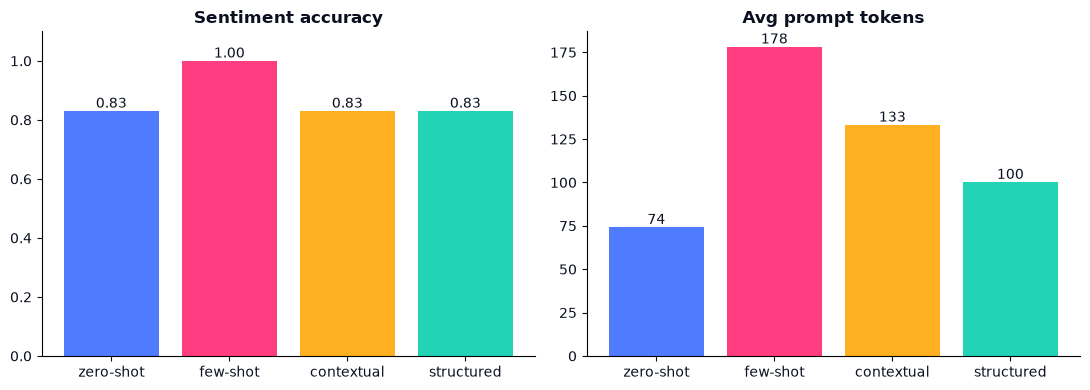

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = [BLUE, PINK, MARIGOLD, MINT]
for ax, col, title in [(axes[0], "sentiment_accuracy", "Sentiment accuracy"), (axes[1], "avg_prompt_tokens", "Avg prompt tokens")]:
    bars = ax.bar(comp.index, comp[col], color=colors)
    ax.bar_label(bars, fmt="%.2f" if col == "sentiment_accuracy" else "%.0f", color=NAVY)
    ax.set_title(title, color=NAVY, fontweight="bold")
    ax.tick_params(colors=NAVY)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
axes[0].set_ylim(0, 1.1)
plt.tight_layout(); plt.show()

## 6. Observations & limitations

- **Few-shot won: 6/6 correct.** The 3 examples taught the model what "neutral" looks like *and* the exact output format. It used the most prompt tokens (178 vs 74 for zero-shot) but was the fastest on average (2.6 s), because its answers were short and consistent.
- **Every strategy got the clear positive/negative reviews right.** Every miss was on the mixed/neutral boundary: zero-shot and structured called *"pool nice but restaurant average"* negative, while contextual over-applied its "mixed = neutral" rule and called the noise complaint neutral.
- **Structured (JSON) gave 100% valid JSON**, which makes it the easiest to plug into code. But topics were free-form ("hotel experience", "HVAC issues"), so a fixed topic list (or few-shot + JSON) would be needed for clean categories.
- **Temperature:** at 0 both seeds were identical (deterministic); 0.7 rephrased but stayed faithful; **1.2 broke down** into hallucinated facts ("inexperienced staff") and random multilingual tokens. Adding `top_p=0.3` at temperature 1.2 made it coherent again; `max_new_tokens=10` cut the answer mid-sentence.
- **System message:** without one the model rambled ("As an AI language model...") and hit the token limit; with one it gave a short sentiment + concrete fix, exactly as instructed.
- **Tokens:** the 6-word sentence is 7 tokens (`Ġ` = leading space). The chat template alone adds ~30 tokens per call, and the 32,768-token context is far more than this task needs.
- **Small-model limits:** the 0.5B model sometimes leaks Chinese words (e.g. "隔音效果" = soundproofing), drifts on topic labels, and needs ~3 s per review on CPU. With only 6 test reviews, one mistake = 17 percentage points, so these accuracy numbers are indicative, not statistically solid.

## 7. Final app: `analyze_review(text)`

Uses the best-scoring strategy from the comparison (ties broken by fewer tokens), greedy decoding, and returns a dict.

In [16]:
best = comp.sort_values(["sentiment_accuracy", "avg_prompt_tokens"], ascending=[False, True]).index[0]
print("Best strategy:", best)

def analyze_review(text):
    """Hotel review -> {'sentiment', 'topic', 'summary'} using the best prompt strategy."""
    reply, _, _ = chat(STRATEGIES[best](text), max_new_tokens=60)
    d = parse_json(reply)
    if not isinstance(d, dict):   # fall back to 'Key: value' lines
        d = {k.lower(): v.strip() for k, v in re.findall(r"(Sentiment|Topic|Summary)\W*:\W*(.+)", reply, re.I)}
    return {"sentiment": get_sentiment(reply), "topic": d.get("topic", "?"), "summary": d.get("summary", reply)}

for r in ["Check-in was quick and the rooftop bar had a stunning sunset view.",
          "The air conditioning was broken and nobody came to fix it for two days."]:
    print(r, "\n ->", analyze_review(r), "\n")

Best strategy: few-shot


Check-in was quick and the rooftop bar had a stunning sunset view. 
 -> {'sentiment': 'positive', 'topic': 'check-in experience', 'summary': "Check-in process was quick and the rooftop bar's stunning sunset view was a highlight."} 



The air conditioning was broken and nobody came to fix it for two days. 
 -> {'sentiment': 'negative', 'topic': 'HVAC issues', 'summary': 'Air conditioning broke down for two consecutive days, leading to inconvenience for guests.'} 

